# Detector de galinhas YOLOPIO

## 1. Imports e configuração

O código importa as bibliotecas, localiza as pastas de dados, pesos e resultados e define os parâmetros do treinamento e da inferência. Também identifica o dispositivo disponível e mostra os caminhos principais.


In [ ]:
from pathlib import Path
import math
import csv

import matplotlib.pyplot as plt
import numpy as np
import torch
from ultralytics import YOLO

candidatos_projeto = (
    Path.cwd() / "src" / "modelos_PIO",
    Path.cwd() / "modelos_PIO",
    Path.cwd(),
    Path.cwd().parent / "src" / "modelos_PIO",
)
PASTA_PROJETO = next(
    (c.resolve() for c in candidatos_projeto
     if (c / "midias" / "PIO" / "data").is_dir()
     and (c / "resultados").is_dir()),
    None,
)
if PASTA_PROJETO is None:
    raise FileNotFoundError(
        "Não encontrei src/modelos_PIO/midias e resultados. "
        "Abra o notebook pela raiz do projeto ou por src/modelos_PIO."
    )

PASTA_MIDIAS = PASTA_PROJETO / "midias"
PASTA_PIO = PASTA_MIDIAS / "PIO" / "data"
ARQUIVO_DADOS = PASTA_PIO / "dataset_local.yaml"
CAMINHO_PESOS_INICIAIS = PASTA_PROJETO / "pesos_iniciais" / "yolo11n.pt"
PASTA_EXECUCOES = PASTA_PROJETO / "resultados" / "treinos_yolo11"
NOME_TREINO = "pio_yolo11n"
CAMINHO_CHECKPOINT = PASTA_EXECUCOES / NOME_TREINO / "weights" / "best.pt"
CAMINHO_ULTIMO = PASTA_EXECUCOES / NOME_TREINO / "weights" / "last.pt"
EXECUTAR_TREINO = False  # True somente para iniciar outra execução
RETOMAR_TREINO = False  # True somente para retomar uma execução interrompida

TAMANHO = 640
EPOCAS = 30
PACIENCIA = 8
BATCH_SIZE = 4
SEMENTE = 42
LIMIAR_CONFIANCA = 0.25
DISPOSITIVO = 0 if torch.cuda.is_available() else "cpu"

print(f"Dados PIO: {PASTA_PIO}")
print(f"Dispositivo: {DISPOSITIVO}")
print(f"Checkpoint esperado: {CAMINHO_CHECKPOINT}")
if DISPOSITIVO == "cpu":
    print("CUDA não foi detectado; o treinamento em CPU pode ser demorado.")

## 2. Conferência da base PIO

O código verifica as imagens e os rótulos das divisões de treino e validação, confere a classe e as coordenadas das caixas e informa anotações sem área. Em seguida, cria a configuração local do conjunto de dados.


In [3]:
EXTENSOES = {".jpg", ".jpeg", ".png"}

for divisao in ("train", "val"):
    pasta_imagens = PASTA_PIO / "images" / divisao
    pasta_rotulos = PASTA_PIO / "labels" / divisao
    if not pasta_imagens.is_dir() or not pasta_rotulos.is_dir():
        raise FileNotFoundError(
            f"Faltam {pasta_imagens} ou {pasta_rotulos}. Extraia data.rar em src/modelos_PIO/midias/PIO para obter a pasta data."
        )

    imagens = sorted(p for p in pasta_imagens.iterdir() if p.suffix.lower() in EXTENSOES)
    if not imagens:
        raise RuntimeError(f"Nenhuma imagem encontrada em {pasta_imagens}.")
    sem_rotulo = [p.name for p in imagens if not (pasta_rotulos / f"{p.stem}.txt").is_file()]
    if sem_rotulo:
        raise FileNotFoundError(
            f"{len(sem_rotulo)} imagens de {divisao} não têm rótulo; exemplos: {sem_rotulo[:5]}"
        )

    degeneradas = []
    for imagem in imagens:
        rotulo = pasta_rotulos / f"{imagem.stem}.txt"
        for numero, linha in enumerate(rotulo.read_text(encoding="utf-8").splitlines(), 1):
            if not linha.strip():
                continue
            partes = linha.split()
            if len(partes) != 5:
                raise ValueError(f"{rotulo}:{numero}: esperadas 5 colunas YOLO.")
            try:
                classe, cx, cy, largura, altura = map(float, partes)
            except ValueError as erro:
                raise ValueError(f"{rotulo}:{numero}: número inválido.") from erro
            if classe != 0 or not all(map(math.isfinite, (cx, cy, largura, altura))):
                raise ValueError(f"{rotulo}:{numero}: somente classe 0 e números finitos.")
            if not all(0 <= valor <= 1 for valor in (cx, cy, largura, altura)):
                raise ValueError(f"{rotulo}:{numero}: coordenadas fora de [0, 1].")
            if largura == 0 or altura == 0:
                degeneradas.append(f"{rotulo.name}:{numero}")

    print(f"{divisao}: {len(imagens)} imagens com rótulo; {len(degeneradas)} caixas de área zero.")
    if degeneradas:
        print("Exemplos para revisar no PIO:", ", ".join(degeneradas[:5]))

conteudo_yaml = (
    f"path: '{PASTA_PIO.resolve().as_posix()}'\n"
    "train: images/train\n"
    "val: images/val\n"
    "names:\n"
    "  0: galinha\n"
)
if not ARQUIVO_DADOS.is_file() or ARQUIVO_DADOS.read_text(encoding="utf-8") != conteudo_yaml:
    ARQUIVO_DADOS.write_text(conteudo_yaml, encoding="utf-8")
print(f"Configuração local: {ARQUIVO_DADOS}")

train: 1035 imagens com rótulo; 3 caixas de área zero.
Exemplos para revisar no PIO: C-W3-0016.txt:332, C-W3-0063.txt:334, C-W6-0128.txt:149
val: 452 imagens com rótulo; 2 caixas de área zero.
Exemplos para revisar no PIO: C-W3-V0038.txt:301, P-W2-V0014.txt:86
Configuração local: C:\Users\Inteli\Documents\2026_02_Raiar\src\arquivos\PIO\data\dataset_local.yaml


## 3. Carregamento dos pesos iniciais

O código carrega o checkpoint inicial YOLO11n pelo Ultralytics e mostra o caminho dos pesos e o número de classes do checkpoint.


In [4]:
try:
    modelo = YOLO(str(CAMINHO_PESOS_INICIAIS))
except Exception as erro:
    raise RuntimeError(
        f"Não consegui carregar {CAMINHO_PESOS_INICIAIS}. "
        "Verifique a conexão ou coloque o yolo11n.pt oficial nessa pasta."
    ) from erro

print(f"Pesos iniciais: {CAMINHO_PESOS_INICIAIS}")
print(f"Classes do checkpoint inicial: {len(modelo.names)}")

Pesos iniciais: C:\Users\Inteli\Documents\2026_02_Raiar\src\arquivos\yolo11n.pt
Classes do checkpoint inicial: 80


## 4. Treinamento ou reutilização do checkpoint

O código confere a configuração da PIO e, com o treinamento desativado, localiza o melhor checkpoint já salvo. Com o treinamento ativado, retoma a execução anterior ou inicia uma nova, salva seus resultados e identifica os melhores pesos.


In [2]:
if not ARQUIVO_DADOS.is_file():
    raise FileNotFoundError(
        f"Não encontrei {ARQUIVO_DADOS}. Execute primeiro a célula de preparação do PIO."
    )

if not EXECUTAR_TREINO:
    if not CAMINHO_CHECKPOINT.is_file():
        raise FileNotFoundError(
            f"Não encontrei {CAMINHO_CHECKPOINT}. Ative EXECUTAR_TREINO para criar um checkpoint."
        )
    print(f"Treino já concluído. Usando: {CAMINHO_CHECKPOINT.resolve()}")
else:
    if RETOMAR_TREINO:
        if not CAMINHO_ULTIMO.is_file():
            raise FileNotFoundError(f"Não encontrei {CAMINHO_ULTIMO}.")
        modelo = YOLO(str(CAMINHO_ULTIMO))
        print(f"Retomando de: {CAMINHO_ULTIMO}")
        resultado_treino = modelo.train(resume=True)
    else:
        if not CAMINHO_PESOS_INICIAIS.is_file():
            raise FileNotFoundError("Execute primeiro a célula que carrega yolo11n.pt.")
        modelo = YOLO(str(CAMINHO_PESOS_INICIAIS))
        resultado_treino = modelo.train(
            data=str(ARQUIVO_DADOS),
            epochs=EPOCAS,
            patience=PACIENCIA,
            imgsz=TAMANHO,
            batch=BATCH_SIZE,
            device=DISPOSITIVO,
            workers=0,
            seed=SEMENTE,
            project=str(PASTA_EXECUCOES),
            name=NOME_TREINO,
            exist_ok=False,
            save=True,
            plots=True,
        )
    CAMINHO_CHECKPOINT = Path(modelo.trainer.best)
    if not CAMINHO_CHECKPOINT.is_file():
        raise FileNotFoundError("O treino terminou, mas não encontrei best.pt.")
    print(f"Melhores pesos: {CAMINHO_CHECKPOINT.resolve()}")

Retomando do último checkpoint: C:\Users\Inteli\Documents\2026_02_Raiar\src\arquivos\treinos_yolo11\pio_yolo11n\weights\last.pt
Ultralytics 8.4.177  Python-3.13.14 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-1345U)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Inteli\Documents\2026_02_Raiar\src\arquivos\PIO\data\dataset_local.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.002, lr

## 5. Histórico por época

O código lê o arquivo de resultados do treinamento, imprime uma tabela com perdas e métricas de cada época e traça as curvas de treino e validação para box, classificação e DFL.


In [ ]:
CAMINHO_HISTORICO = CAMINHO_CHECKPOINT.parents[1] / "results.csv"
if not CAMINHO_HISTORICO.is_file():
    raise FileNotFoundError(
        f"Não encontrei {CAMINHO_HISTORICO}. É preciso concluir ao menos uma época de treino."
    )

with CAMINHO_HISTORICO.open(newline="", encoding="utf-8") as arquivo:
    historico = [
        {chave.strip(): float(valor) for chave, valor in linha.items()}
        for linha in csv.DictReader(arquivo)
    ]
if not historico:
    raise RuntimeError(f"O histórico está vazio: {CAMINHO_HISTORICO}")


colunas = [
    ("Época", 5), ("Box treino", 10), ("Box val", 8),
    ("Cls treino", 10), ("Cls val", 8),
    ("DFL treino", 10), ("DFL val", 8),
    ("Precisão", 9), ("Recall", 7), ("mAP50", 7), ("mAP50-95", 10),
]
print(" | ".join(f"{nome:>{largura}}" for nome, largura in colunas))
print("-+-".join("-" * largura for _, largura in colunas))
for r in historico:
    valores = [
        f"{int(r['epoch'])}",
        f"{r['train/box_loss']:.3f}", f"{r['val/box_loss']:.3f}",
        f"{r['train/cls_loss']:.3f}", f"{r['val/cls_loss']:.3f}",
        f"{r['train/dfl_loss']:.3f}", f"{r['val/dfl_loss']:.3f}",
        f"{100 * r['metrics/precision(B)']:.1f}%",
        f"{100 * r['metrics/recall(B)']:.1f}%",
        f"{100 * r['metrics/mAP50(B)']:.1f}%",
        f"{100 * r['metrics/mAP50-95(B)']:.1f}%",
    ]
    print(" | ".join(f"{valor:>{largura}}" for valor, (_, largura) in zip(valores, colunas)))

epocas = [int(registro["epoch"]) for registro in historico]
figura, eixos = plt.subplots(1, 3, figsize=(17, 4.5), sharex=True)
for eixo, nome, chave in zip(eixos, ("Box", "Classificação", "DFL"), ("box", "cls", "dfl")):
    eixo.plot(epocas, [r[f"train/{chave}_loss"] for r in historico], label="Treino")
    eixo.plot(epocas, [r[f"val/{chave}_loss"] for r in historico], label="Validação")
    eixo.set_title(f"Perda {nome}")
    eixo.set_xlabel("Época")
    eixo.set_ylabel("Valor da perda")
    eixo.grid(alpha=0.25)
    eixo.legend()
figura.tight_layout()
plt.show()

## 6. Validação na PIO

O código carrega o melhor checkpoint, executa a validação na divisão val da PIO e mostra os valores de mAP@0,50 e mAP@0,50:0,95.


In [9]:
if not CAMINHO_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Não encontrei {CAMINHO_CHECKPOINT}. Treine o modelo ou ajuste CAMINHO_CHECKPOINT."
    )

detector = YOLO(str(CAMINHO_CHECKPOINT))
metricas_pio = detector.val(
    data=str(ARQUIVO_DADOS),
    split="val",
    imgsz=TAMANHO,
    batch=BATCH_SIZE,
    device=DISPOSITIVO,
    workers=0,
    project=str(PASTA_EXECUCOES),
    name="pio_yolo11n_validacao",
    exist_ok=False,
    plots=True,
)
print(f"PIO mAP@0.50: {metricas_pio.box.map50:.4f}")
print(f"PIO mAP@0.50:0.95: {metricas_pio.box.map:.4f}")

Ultralytics 8.4.177  Python-3.13.14 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-1345U)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 454.8±358.2 MB/s, size: 925.5 KB)
val: Scanning C:\Users\Inteli\Documents\2026_02_Raiar\src\arquivos\PIO\data\labels\val.cache... 452 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 452/452 37.2Mit/s 0.0s
WARNING Dataset images contain up to 594 objects (val=594), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=594 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 113/113 1.3it/s 1:300.7ss
                   all        452      73859      0.928      0.897      0.945      0.639
Speed: 1.6ms preprocess, 95.9ms inference, 

## 7. Erro de contagem na PIO

O código lê os rótulos da validação, conta as caixas previstas em cada imagem e compara essa quantidade com as anotações válidas. Calcula MAE, RMSE, MAPE, viés médio e totais de galinhas anotadas e detectadas.


In [10]:
if not CAMINHO_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Não encontrei {CAMINHO_CHECKPOINT}.")
if "metricas_pio" not in globals():
    raise RuntimeError("Execute primeiro a célula de validação PIO.")

pasta_imagens_val = PASTA_PIO / "images" / "val"
pasta_rotulos_val = PASTA_PIO / "labels" / "val"
if not pasta_imagens_val.is_dir() or not pasta_rotulos_val.is_dir():
    raise FileNotFoundError("Não encontrei as imagens e os rótulos de validação do PIO.")

def ler_contagem_real(caminho):
    if not caminho.is_file():
        raise FileNotFoundError(f"Rótulo ausente: {caminho}")
    quantidade = 0
    ignoradas = 0
    for numero, linha in enumerate(caminho.read_text(encoding="utf-8").splitlines(), 1):
        if not linha.strip():
            continue
        campos = linha.split()
        if len(campos) != 5:
            raise ValueError(f"{caminho}:{numero}: esperado classe, cx, cy, largura e altura.")
        try:
            classe, cx, cy, largura, altura = map(float, campos)
        except ValueError as erro:
            raise ValueError(f"{caminho}:{numero}: valor não numérico.") from erro
        if classe != 0 or not all(map(math.isfinite, (cx, cy, largura, altura))):
            raise ValueError(f"{caminho}:{numero}: classe ou coordenadas inválidas.")
        if largura <= 0 or altura <= 0:
            ignoradas += 1
            continue
        quantidade += 1
    return quantidade, ignoradas

detector_contagem = YOLO(str(CAMINHO_CHECKPOINT))
contagens_pio = []
total_ignoradas = 0
print("Comparando a quantidade detectada e a anotada em cada imagem de validação PIO...")

for resultado in detector_contagem.predict(
    source=str(pasta_imagens_val),
    stream=True,
    imgsz=TAMANHO,
    conf=LIMIAR_CONFIANCA,
    max_det=1000,
    device=DISPOSITIVO,
    verbose=False,
):
    caminho_imagem = Path(resultado.path)
    rotulo = pasta_rotulos_val / f"{caminho_imagem.stem}.txt"
    real, ignoradas = ler_contagem_real(rotulo)
    prevista = len(resultado.boxes)
    total_ignoradas += ignoradas
    contagens_pio.append({
        "imagem": caminho_imagem.name,
        "real": real,
        "prevista": prevista,
        "erro": prevista - real,
    })

if not contagens_pio:
    raise RuntimeError("Nenhuma imagem foi encontrada na divisão de validação PIO.")

reais = np.asarray([item["real"] for item in contagens_pio], dtype=np.float64)
previstas = np.asarray([item["prevista"] for item in contagens_pio], dtype=np.float64)
diferencas = previstas - reais
mae_contagem = float(np.mean(np.abs(diferencas)))
rmse_contagem = float(np.sqrt(np.mean(np.square(diferencas))))
vies_contagem = float(np.mean(diferencas))
com_galinhas = reais > 0
imagens_sem_galinhas = int((~com_galinhas).sum())
mape_contagem = (
    float(100 * np.mean(np.abs(diferencas[com_galinhas]) / reais[com_galinhas]))
    if np.any(com_galinhas) else None
)

linhas_resumo = [
    ("Precisão PIO", f"{100 * metricas_pio.box.mp:.2f}%"),
    ("Recall PIO", f"{100 * metricas_pio.box.mr:.2f}%"),
    ("mAP@0,50 PIO", f"{100 * metricas_pio.box.map50:.2f}%"),
    ("mAP@0,50:0,95 PIO", f"{100 * metricas_pio.box.map:.2f}%"),
    ("MAE da contagem", f"{mae_contagem:.2f} galinhas/imagem"),
    ("RMSE da contagem", f"{rmse_contagem:.2f} galinhas/imagem"),
    ("MAPE da contagem", f"{mape_contagem:.2f}%" if mape_contagem is not None else "indefinido"),
    ("Viés médio da contagem", f"{vies_contagem:+.2f} galinhas/imagem"),
    ("Total anotado na validação", f"{int(reais.sum())} galinhas"),
    ("Total detectado na validação", f"{int(previstas.sum())} detecções"),
]

Comparando a quantidade detectada e a anotada em cada imagem de validação PIO...


## 8. Tabela dos indicadores

O código imprime as métricas de detecção e contagem calculadas, informa a quantidade de imagens avaliadas e lista as dez maiores diferenças de contagem na PIO.


In [11]:
if "linhas_resumo" not in globals() or "contagens_pio" not in globals():
    raise RuntimeError("Execute primeiro a célula que calcula os erros de contagem.")

largura_nome = max(len("Métrica"), *(len(nome) for nome, _ in linhas_resumo))
largura_valor = max(len("Resultado"), *(len(valor) for _, valor in linhas_resumo))
print(f"{'Métrica':<{largura_nome}} | {'Resultado':>{largura_valor}}")
print(f"{'-' * largura_nome}-+-{'-' * largura_valor}")
for nome, valor in linhas_resumo:
    print(f"{nome:<{largura_nome}} | {valor:>{largura_valor}}")

print(
    f"\nImagens avaliadas: {len(contagens_pio)}; "
    f"anotações de área zero ignoradas: {total_ignoradas}; "
    f"imagens sem galinhas excluídas do MAPE: {imagens_sem_galinhas}."
)
print("\nMaiores diferenças de contagem (PIO):")
print(f"{'Imagem':<28} {'Real':>7} {'Detectadas':>12} {'Erro':>7}")
for item in sorted(contagens_pio, key=lambda item: abs(item["erro"]), reverse=True)[:10]:
    print(f"{item['imagem']:<28} {item['real']:>7} {item['prevista']:>12} {item['erro']:>+7}")

Métrica                      |              Resultado
-----------------------------+-----------------------
Precisão PIO                 |                 92.78%
Recall PIO                   |                 89.67%
mAP@0,50 PIO                 |                 94.52%
mAP@0,50:0,95 PIO            |                 63.93%
MAE da contagem              |  20.92 galinhas/imagem
RMSE da contagem             |  31.18 galinhas/imagem
MAPE da contagem             |                 11.72%
Viés médio da contagem       | +19.79 galinhas/imagem
Total anotado na validação   |         73857 galinhas
Total detectado na validação |        82802 detecções

Imagens avaliadas: 452; anotações de área zero ignoradas: 2; imagens sem galinhas excluídas do MAPE: 0.

Maiores diferenças de contagem (PIO):
Imagem                          Real   Detectadas    Erro
C-W2-V0057.jpg                   536          677    +141
C-W1-V0013.jpg                   498          632    +134
C-W2-V0056.jpg                   4

## 9. Inspeção dos vídeos da Raiar

O código seleciona até três frames de cada vídeo da Raiar, aplica o detector, desenha as caixas previstas e exibe a quantidade detectada em cada frame.


Câmera Raiar | camera-raiar_t0000s.jpg: 1 detecções
Câmera Raiar | camera-raiar_t0300s.jpg: 1 detecções
Câmera Raiar | camera-raiar_t0598s.jpg: 1 detecções
Segundo vídeo | video-galinhas2_t0000s.jpg: 32 detecções
Segundo vídeo | video-galinhas2_t0008s.jpg: 32 detecções
Segundo vídeo | video-galinhas2_t0014s.jpg: 43 detecções


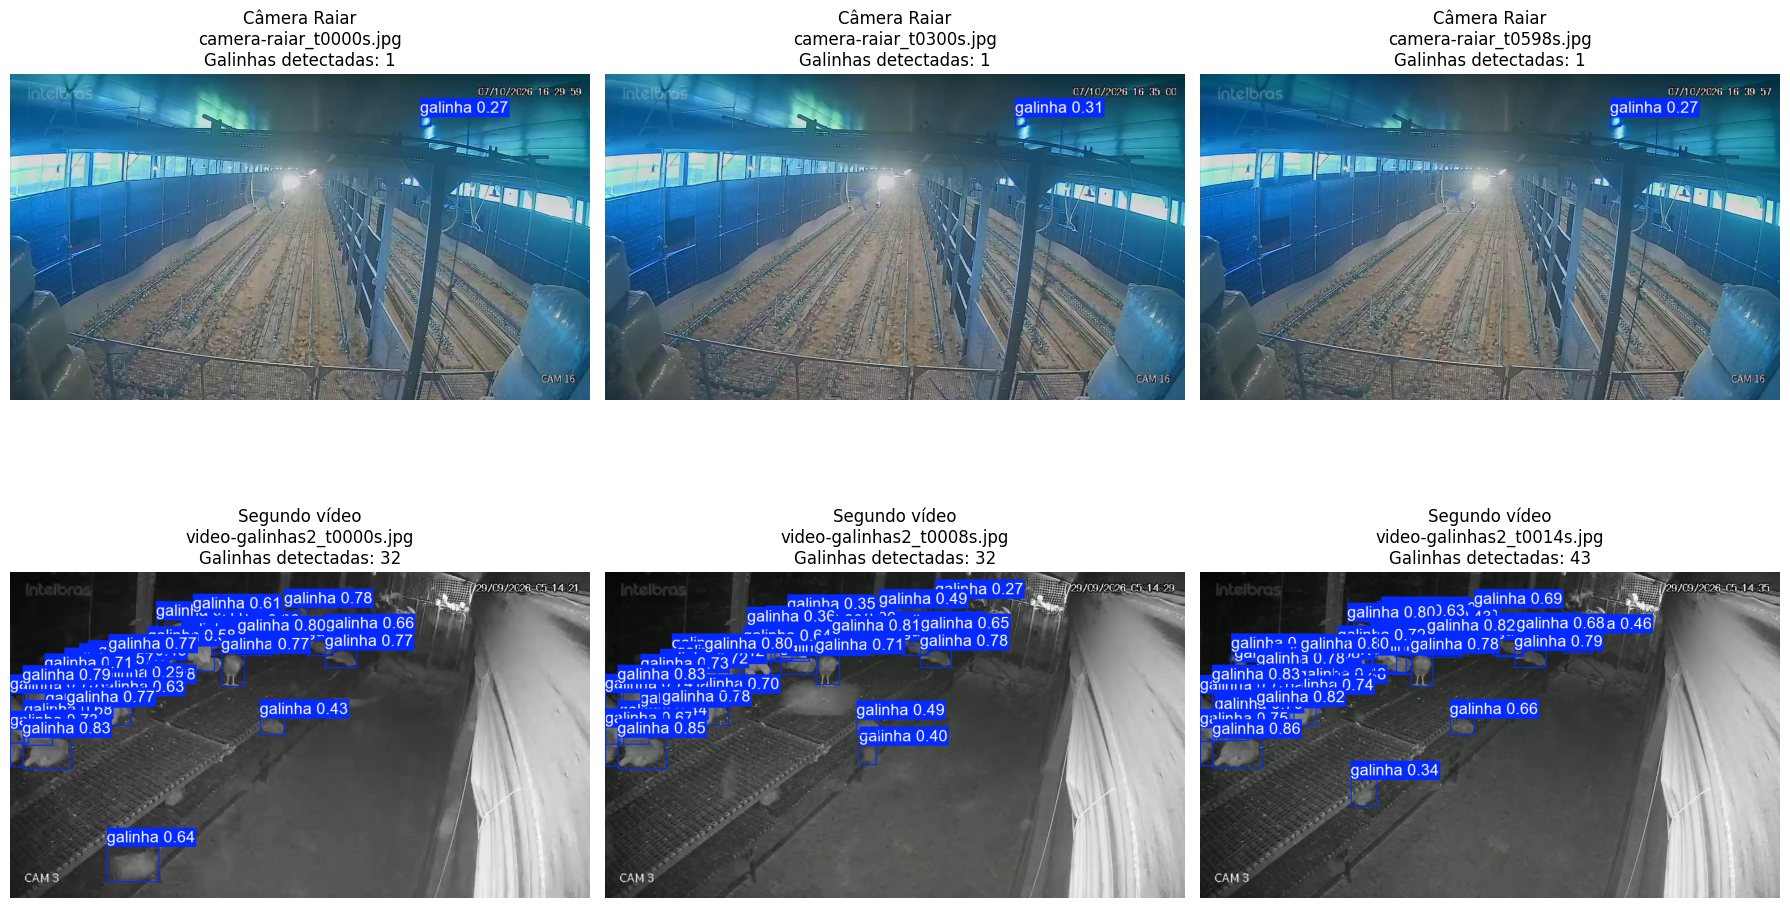

In [12]:
if not CAMINHO_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Não encontrei {CAMINHO_CHECKPOINT}. Treine ou indique o best.pt salvo."
    )

detector = YOLO(str(CAMINHO_CHECKPOINT))
grupos = {
    "Câmera Raiar": sorted((PASTA_MIDIAS / "raiar" / "camera-raiar" / "frames").glob("camera-raiar_t????s.jpg")),
    "Segundo vídeo": sorted((PASTA_MIDIAS / "raiar" / "video-galinhas2" / "frames").glob("video-galinhas2_t????s.jpg")),
}
for nome, frames in grupos.items():
    if not frames:
        raise FileNotFoundError(
            f"Não encontrei frames de {nome} em {PASTA_MIDIAS / 'raiar'}. "
            "Gere os frames no notebook de análise de imagens."
        )

figura, eixos = plt.subplots(2, 3, figsize=(18, 11))
for linha, (nome, frames) in enumerate(grupos.items()):
    indices = list(dict.fromkeys((0, len(frames) // 2, len(frames) - 1)))
    for coluna, indice in enumerate(indices):
        caminho = frames[indice]
        resultado = detector.predict(
            source=str(caminho),
            imgsz=TAMANHO,
            conf=LIMIAR_CONFIANCA,
            max_det=1000,
            device=DISPOSITIVO,
            save=False,
            verbose=False,
        )[0]
        quantidade = len(resultado.boxes)
        eixos[linha, coluna].imshow(resultado.plot(pil=True))
        eixos[linha, coluna].set_title(
            f"{nome}\n{caminho.name}\nGalinhas detectadas: {quantidade}"
        )
        eixos[linha, coluna].axis("off")
        print(f"{nome} | {caminho.name}: {quantidade} detecções")
    for coluna in range(len(indices), 3):
        eixos[linha, coluna].axis("off")

figura.tight_layout()
plt.show()